# MNIST Exploration

EDA and results analysis — core pipeline logic lives in `src/`. The checks below mirror `MNISTDataModule._load_and_clean()` exactly, run here separately so the actual counts (and the class-balance/sample-image visuals) are inspectable and presentable on their own, rather than only asserted in prose in `README.md`/`REPORT.md`.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Basic shape, and confirming the test.csv split-strategy assumption

Kaggle's `test.csv` is for leaderboard submission only — it should have no `label` column. This is why the project's entire 60/20/20 split comes from `train.csv` alone; confirmed here rather than assumed.

In [2]:
print('train shape:', train.shape)
print('test shape:', test.shape)
print("'label' in test.csv columns:", 'label' in test.columns)

train shape: (42000, 785)
test shape: (28000, 784)
'label' in test.csv columns: False


## Data cleaning checks

Five checks, matching `_load_and_clean()` in `src/data_module.py`: missing values, exact duplicate rows, pixel values outside `[0, 255]`, label values outside `[0, 9]`, and blank (all-zero) images. Reported here as counts rather than applied as filters, since this cell is for inspection — the pipeline itself applies the actual filtering at training time.

In [3]:
pixel_cols = [c for c in train.columns if c != 'label']

missing = train.isna().sum().sum()
duplicates = train.duplicated().sum()
pixel_out_of_range = (~train[pixel_cols].apply(lambda col: col.between(0, 255)).all(axis=1)).sum()
label_out_of_range = (~train['label'].between(0, 9)).sum()
blank_images = (train[pixel_cols].sum(axis=1) == 0).sum()

print(f'Missing values: {missing}')
print(f'Duplicate rows: {duplicates}')
print(f'Rows with pixel values outside [0, 255]: {pixel_out_of_range}')
print(f'Rows with label outside [0, 9]: {label_out_of_range}')
print(f'Blank (all-zero) images: {blank_images}')

Missing values: 0
Duplicate rows: 0
Rows with pixel values outside [0, 255]: 0
Rows with label outside [0, 9]: 0
Blank (all-zero) images: 0


## Class balance

Verified rather than assumed — close to uniform would mean no imbalance-handling techniques (weighted sampling, class-weighted loss, focal loss) are needed.

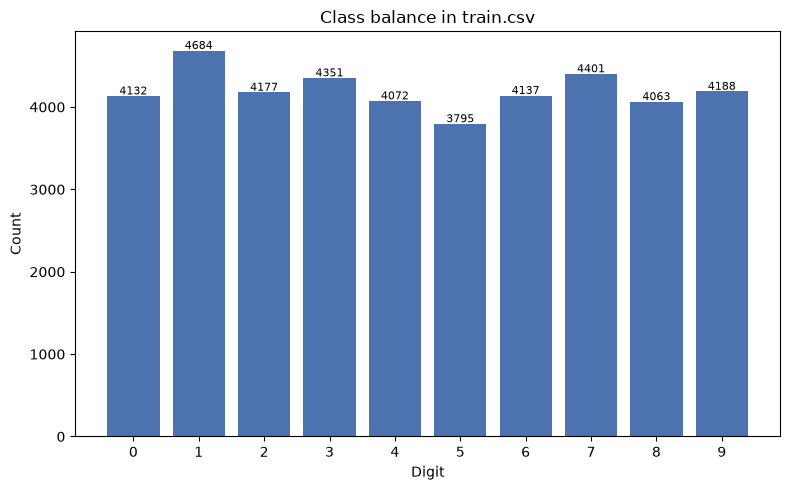

Range: 9.04% - 11.15%


In [4]:
counts = train['label'].value_counts().sort_index()
percentages = counts / len(train) * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(counts.index, counts.values, color='#4C72B0')
ax.set_xlabel('Digit')
ax.set_ylabel('Count')
ax.set_title('Class balance in train.csv')
ax.set_xticks(range(10))
for i, v in zip(counts.index, counts.values):
    ax.text(i, v + 20, str(v), ha='center', fontsize=8)
fig.tight_layout()
plt.show()

print(f'Range: {percentages.min():.2f}% - {percentages.max():.2f}%')

## Sample images

One example per digit, straight from the raw pixel columns (no preprocessing) — a basic visual sanity check that labels and pixel data actually correspond to what they claim.

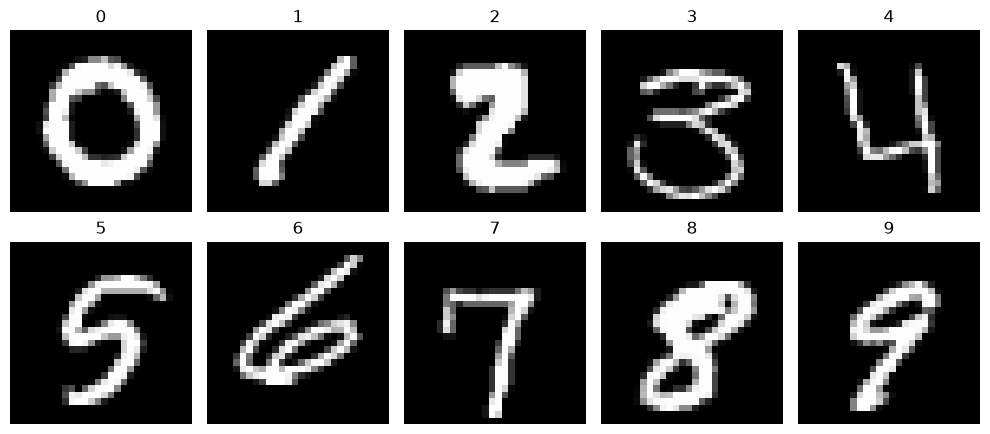

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit in range(10):
    row = train[train['label'] == digit].iloc[0]
    image = row[pixel_cols].to_numpy(dtype=np.uint8).reshape(28, 28)
    ax = axes[digit // 5, digit % 5]
    ax.imshow(image, cmap='gray')
    ax.set_title(str(digit))
    ax.axis('off')
fig.tight_layout()
plt.show()

## Pixel intensity distribution

Mostly-black backgrounds dominate every image, so a log-scale y-axis is needed to see the (much smaller) spread of stroke-intensity values — motivates normalizing to `[0, 1]` before training rather than using raw `[0, 255]` values directly.

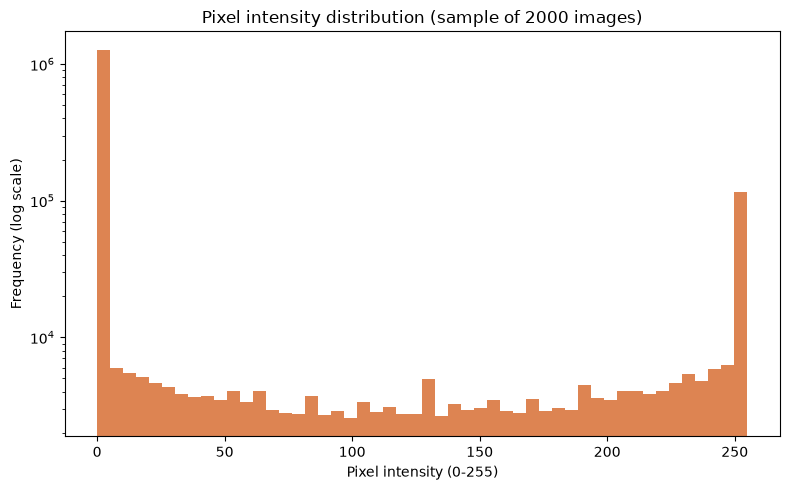

In [6]:
sample = train[pixel_cols].sample(2000, random_state=42).to_numpy().flatten()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(sample, bins=50, color='#DD8452')
ax.set_xlabel('Pixel intensity (0-255)')
ax.set_ylabel('Frequency (log scale)')
ax.set_yscale('log')
ax.set_title('Pixel intensity distribution (sample of 2000 images)')
fig.tight_layout()
plt.show()

## Summary

All five cleaning checks come back at zero — the data is already clean. Classes are close to uniform (see the range printed above), so no imbalance handling is needed. Both findings are used as-is in `README.md` and `REPORT.md` §1; the checks themselves are permanently baked into `src/data_module.py` as guardrails, not just run once here and forgotten.